## Install required packages

In [1]:
# Uncomment if running locally and missing packages
%pip install pandas numpy matplotlib seaborn scikit-learn nltk kagglehub

## **Cell 1:** Import Libraries

In [2]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings('ignore')
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

True

## **Cell 2:** Download & Load the Dataset

In [3]:
path = kagglehub.dataset_download("ankurzing/sentiment-analysis-for-financial-news")
csv_path = os.path.join(path, "all-data.csv")

# Load dataset with latin-1 encoding and assign column names
df = pd.read_csv(csv_path, encoding='latin-1', header=None, names=['Sentiment', 'News Headline'])

print(f"Initial Dataset Shape: {df.shape}")
df.head()

100%|██████████| 903k/903k [00:00<00:00, 63.1MB/s]

Extracting files...
Initial Dataset Shape: (4846, 2)


,Sentiment,News Headline
0,neutral,"According to Gran , the company has no plans t..."
1,neutral,Technopolis plans to develop in stages an area...
2,negative,The international electronic industry company ...
3,positive,With the new production plant the company woul...
4,positive,According to the company 's updated strategy f...


## **Cell 3:** Exploratory Data Analysis (EDA) & Data Cleaning

Missing Values:
 Sentiment        0
News Headline    0
dtype: int64

Duplicates found: 6
Shape after removing duplicates: (4840, 2)

Sentiment
neutral     2873
positive    1363
negative     604
Name: count, dtype: int64


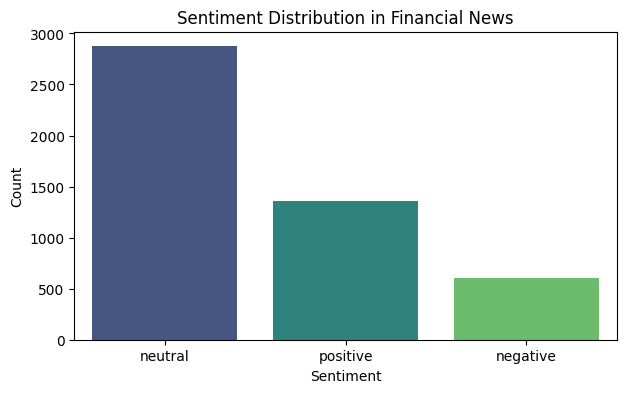

In [4]:
# Check missing values and remove duplicates
print("Missing Values:\n", df.isnull().sum())
print(f"\nDuplicates found: {df.duplicated().sum()}")

df = df.drop_duplicates().reset_index(drop=True)
df['Sentiment'] = df['Sentiment'].str.strip().str.lower()
print(f"Shape after removing duplicates: {df.shape}\n")

# Class distribution
print(df['Sentiment'].value_counts())

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Sentiment', palette='viridis', order=['neutral', 'positive', 'negative'])
plt.title('Sentiment Distribution in Financial News')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()

## **Cell 4:** Text Preprocessing & TF-IDF Vectorization

In [5]:
lemmatizer = WordNetLemmatizer()

# Keep financial directional and negation words
stop_words = set(stopwords.words('english')) - {
    'not', 'no', 'nor', 'up', 'down', 'above', 'below', 'under', 'over', 'more', 'less'
}

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = [lemmatizer.lemmatize(w) for w in text.split() if w not in stop_words]
    return ' '.join(tokens)

df['Cleaned_Headline'] = df['News Headline'].apply(preprocess_text)

# 80/20 Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    df['Cleaned_Headline'],
    df['Sentiment'],
    test_size=0.2,
    random_state=42,
    stratify=df['Sentiment']
)

# Convert text into TF-IDF feature vectors
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"Training matrix shape: {X_train_tfidf.shape}")
print(f"Testing matrix shape:  {X_test_tfidf.shape}")

Training matrix shape: (3872, 5000)
Testing matrix shape:  (968, 5000)


## **Cell 5:** Train & Evaluate (Logistic Regression, SVM, Random Forest)

In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM": SVC(kernel='linear', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test_tfidf)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    results.append({"Model": name, "Accuracy": acc, "Macro F1-Score": f1})

    print(f"=== {name} (Accuracy: {acc:.4f} | Macro F1: {f1:.4f}) ===")
    print(classification_report(y_test, y_pred))
    print("-" * 55)

=== Logistic Regression (Accuracy: 0.7479 | Macro F1: 0.6654) ===
              precision    recall  f1-score   support

    negative       0.83      0.45      0.59       121
     neutral       0.74      0.94      0.83       575
    positive       0.75      0.47      0.58       272

    accuracy                           0.75       968
   macro avg       0.77      0.62      0.67       968
weighted avg       0.75      0.75      0.73       968

-------------------------------------------------------
=== SVM (Accuracy: 0.7469 | Macro F1: 0.6812) ===
              precision    recall  f1-score   support

    negative       0.75      0.53      0.62       121
     neutral       0.76      0.90      0.82       575
    positive       0.71      0.52      0.60       272

    accuracy                           0.75       968
   macro avg       0.74      0.65      0.68       968
weighted avg       0.74      0.75      0.73       968

-------------------------------------------------------
=== Random

## **Cell 6:** Model Comparison Chart & Confusion Matrices

In [11]:
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

              Model  Accuracy  Macro F1-Score
Logistic Regression  0.747934        0.665410
                SVM  0.746901        0.681194
      Random Forest  0.741736        0.658888


### Cell 6.1: Accuracy & Macro F1 Bar Chart

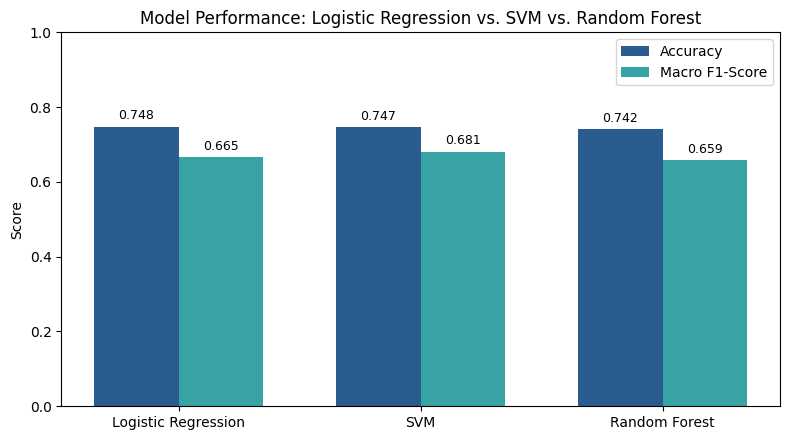

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(results_df['Model']))
width = 0.35

rects1 = ax.bar(x - width/2, results_df['Accuracy'], width, label='Accuracy', color='#2b5c8f')
rects2 = ax.bar(x + width/2, results_df['Macro F1-Score'], width, label='Macro F1-Score', color='#38a3a5')

ax.set_ylabel('Score')
ax.set_title('Model Performance: Logistic Regression vs. SVM vs. Random Forest')
ax.set_xticks(x)
ax.set_xticklabels(results_df['Model'])
ax.set_ylim(0, 1.0)
ax.legend()

for rect in rects1 + rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Cell 6.2: Confusion Matrices for all 3 models

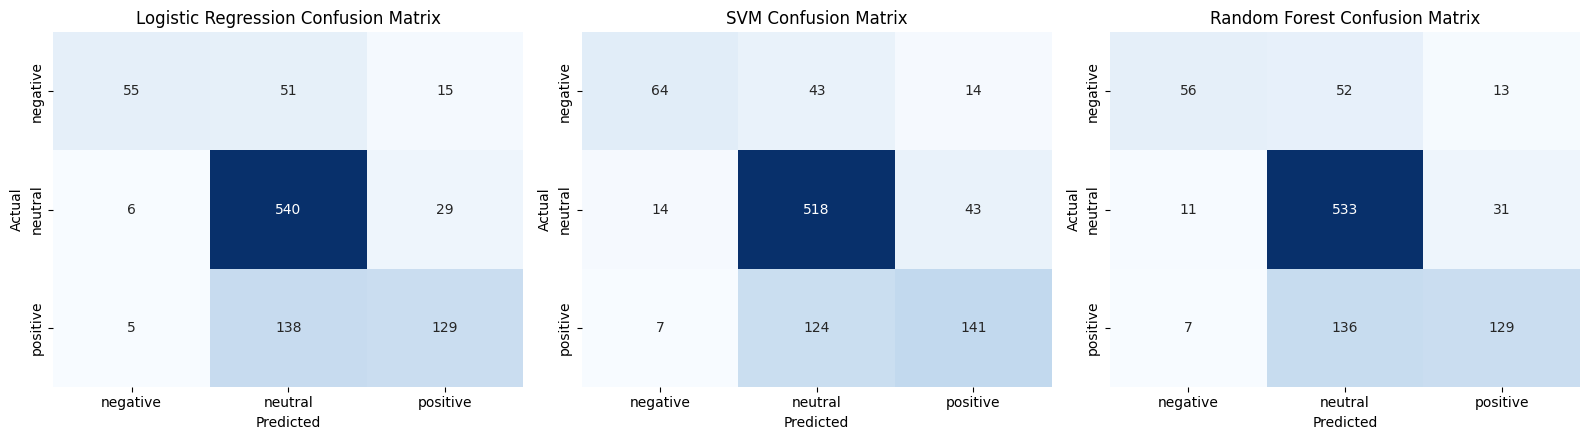

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
labels = ['negative', 'neutral', 'positive']

for ax, (name, model) in zip(axes, trained_models.items()):
    preds = model.predict(X_test_tfidf)
    cm = confusion_matrix(y_test, preds, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

### Plot Decision Trees for All 3 Models (Actual Tree for RF + Surrogate Trees for LR & SVM)

1. Random Forest: Plot its actual internal Decision Tree (rf_model.estimators_[0]).

2. Logistic Regression & SVM: Plot a Surrogate Decision Tree—a standard Explainable AI (XAI) technique where a Decision Tree is trained on the predictions of Logistic Regression and SVM to visualize their decision rules as a tree, alongside their top feature-weight plots.

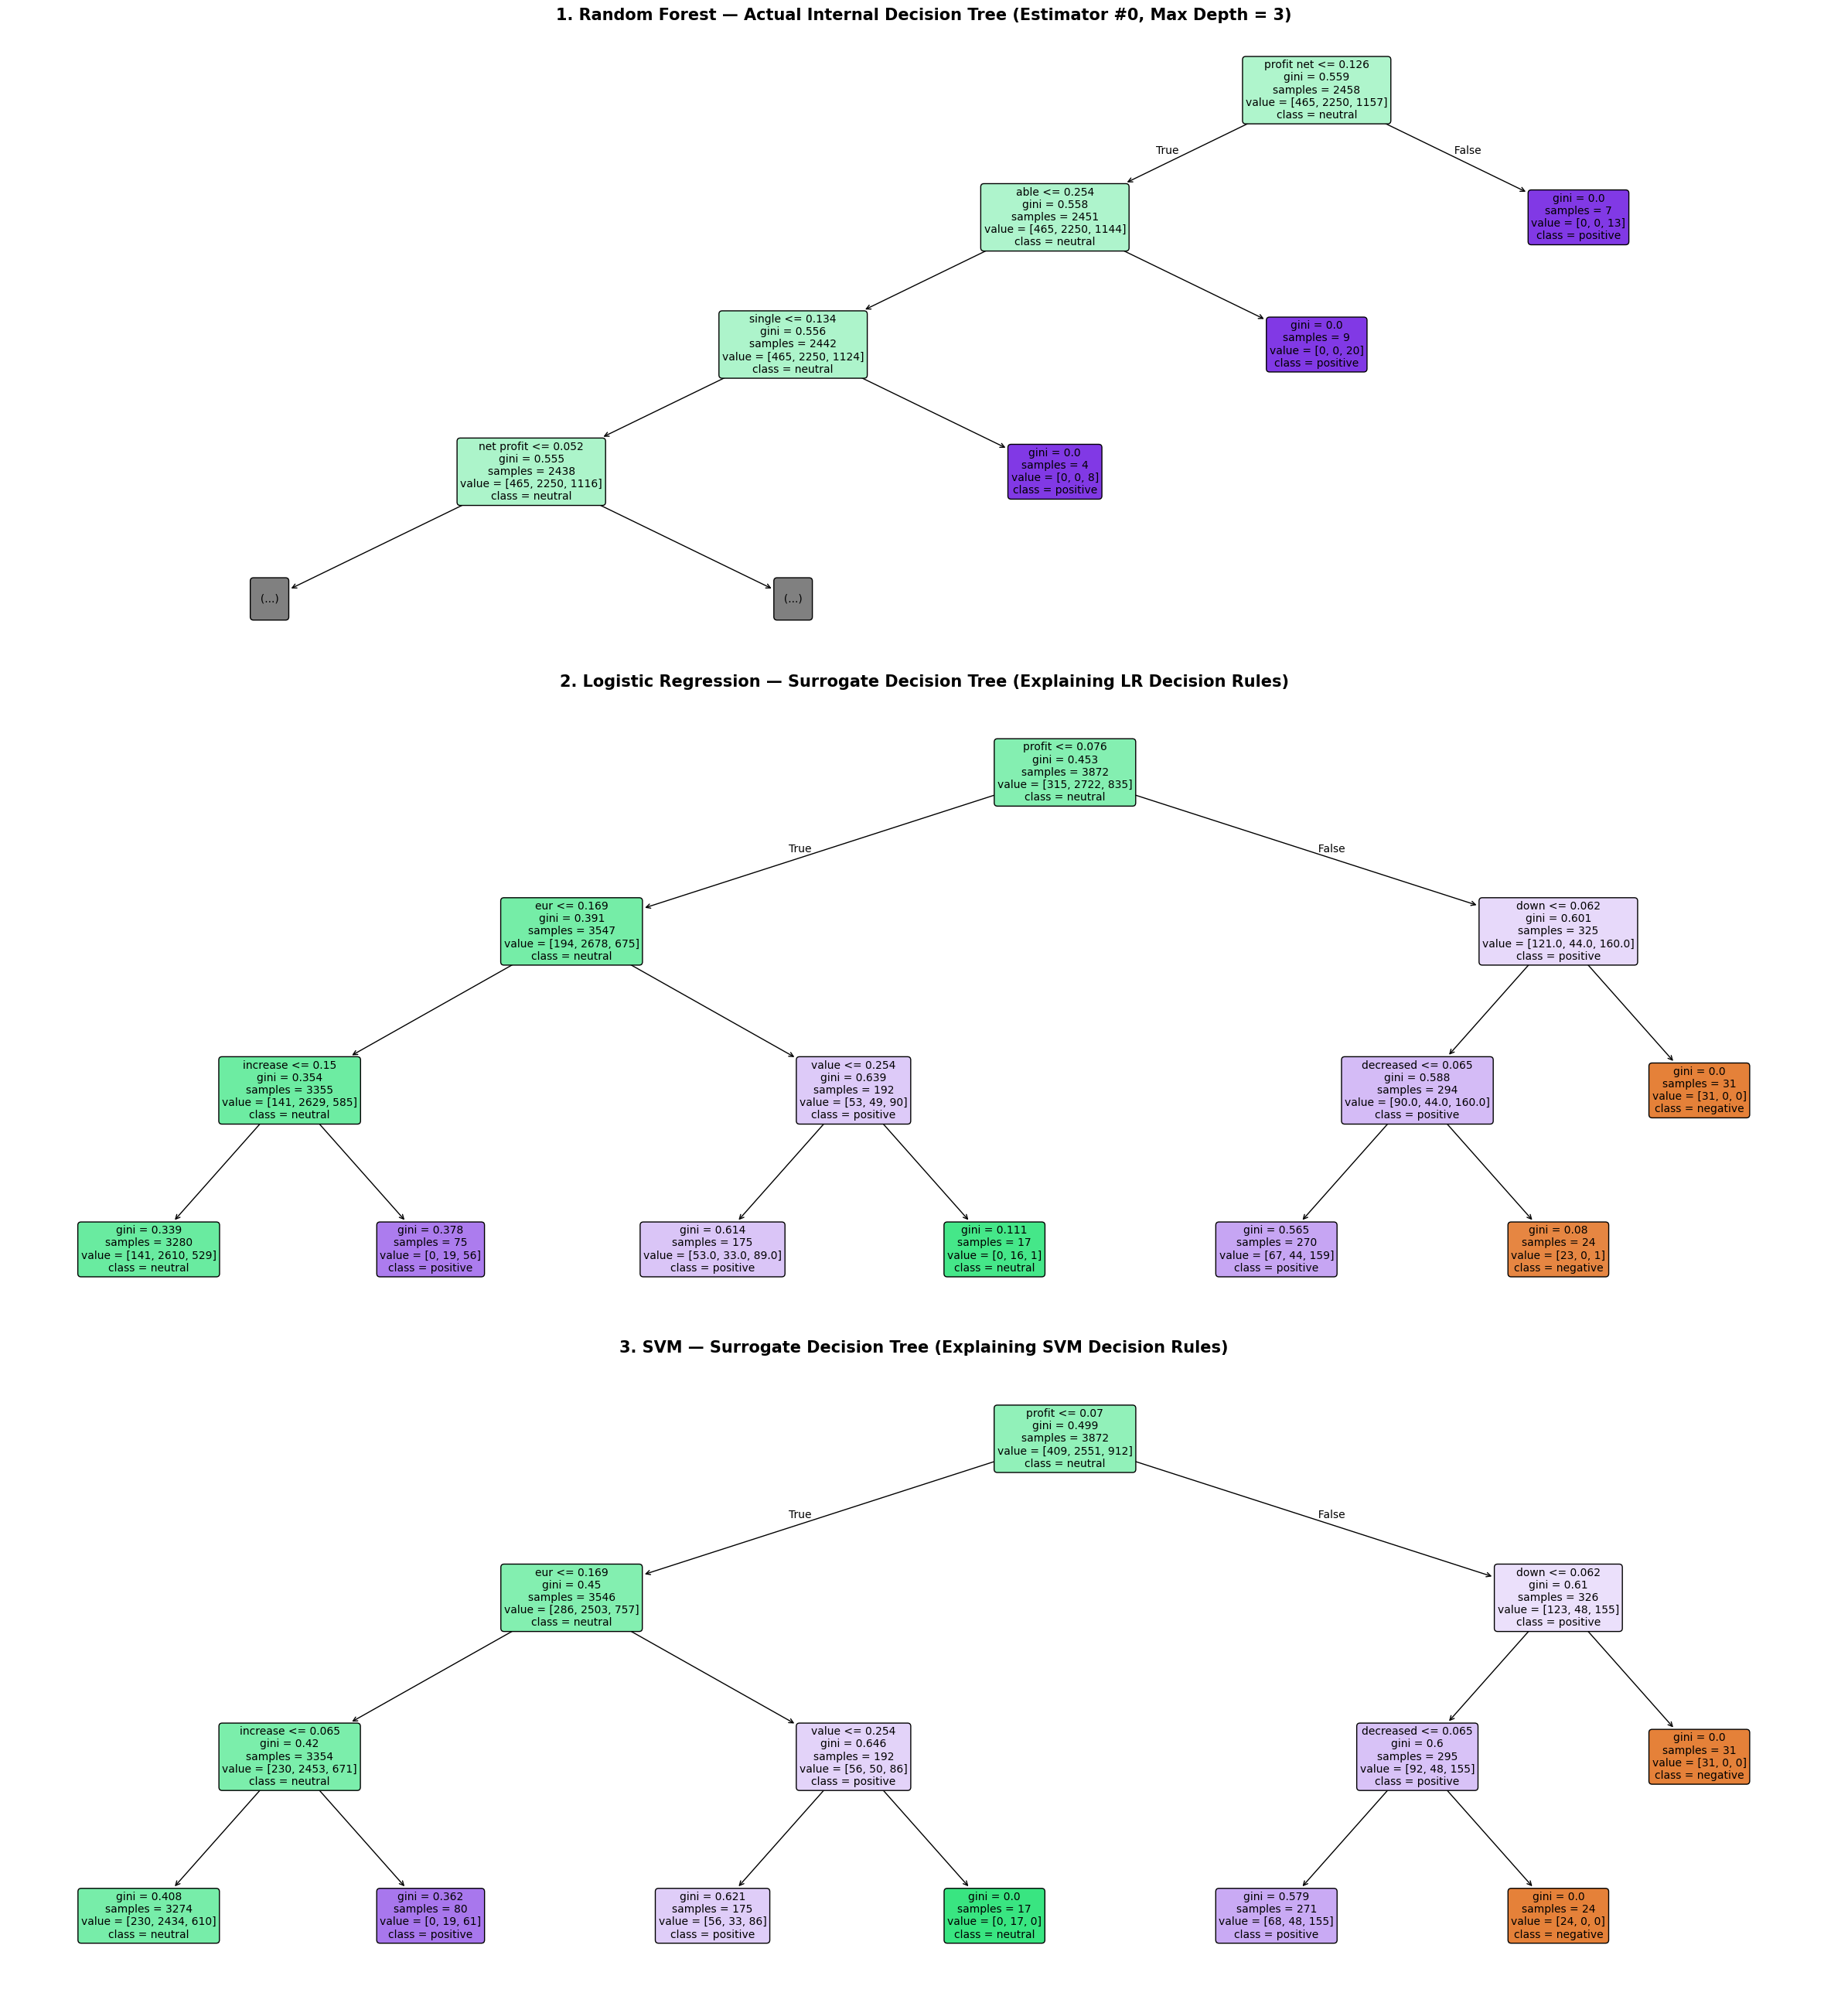

In [14]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

feature_names = tfidf.get_feature_names_out()
class_names = ['negative', 'neutral', 'positive']

fig, axes = plt.subplots(3, 1, figsize=(24, 26))

# 1. RANDOM FOREST: Plot an actual Decision Tree from the forest
rf_single_tree = trained_models["Random Forest"].estimators_[0]
plot_tree(
    rf_single_tree,
    max_depth=3,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=10,
    ax=axes[0]
)
axes[0].set_title("1. Random Forest — Actual Internal Decision Tree (Estimator #0, Max Depth = 3)", fontsize=15, fontweight='bold')

# 2. LOGISTIC REGRESSION: Train & plot a Surrogate Decision Tree explaining LR's predictions
lr_preds_train = trained_models["Logistic Regression"].predict(X_train_tfidf)
lr_surrogate_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
lr_surrogate_tree.fit(X_train_tfidf, lr_preds_train)

plot_tree(
    lr_surrogate_tree,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=10,
    ax=axes[1]
)
axes[1].set_title("2. Logistic Regression — Surrogate Decision Tree (Explaining LR Decision Rules)", fontsize=15, fontweight='bold')

# 3. SVM: Train & plot a Surrogate Decision Tree explaining SVM's predictions
svm_preds_train = trained_models["SVM"].predict(X_train_tfidf)
svm_surrogate_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
svm_surrogate_tree.fit(X_train_tfidf, svm_preds_train)

plot_tree(
    svm_surrogate_tree,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=10,
    ax=axes[2]
)
axes[2].set_title("3. SVM — Surrogate Decision Tree (Explaining SVM Decision Rules)", fontsize=15, fontweight='bold')

plt.tight_layout()
plt.show()

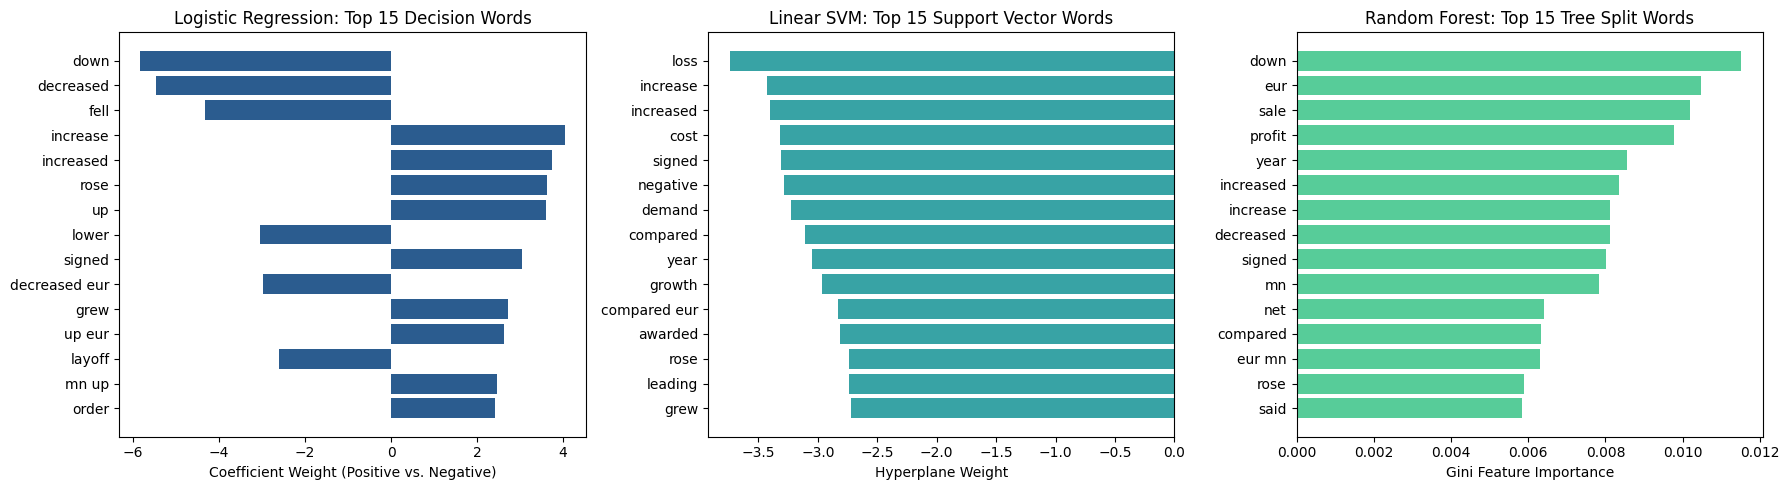

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Logistic Regression Top Words (Positive vs Negative Coefficients)
lr_model = trained_models["Logistic Regression"]
# Index 2 is 'positive', Index 0 is 'negative'
lr_coef = lr_model.coef_[2] - lr_model.coef_[0]
top_lr_idx = np.argsort(np.abs(lr_coef))[-15:]
axes[0].barh(feature_names[top_lr_idx], lr_coef[top_lr_idx], color='#2b5c8f')
axes[0].set_title("Logistic Regression: Top 15 Decision Words")
axes[0].set_xlabel("Coefficient Weight (Positive vs. Negative)")

# 2. Linear SVM Top Words (Support Vector Weights)
svm_model = trained_models["SVM"]
svm_coef = svm_model.coef_[2].toarray().flatten() - svm_model.coef_[0].toarray().flatten()
top_svm_idx = np.argsort(np.abs(svm_coef))[-15:]
axes[1].barh(feature_names[top_svm_idx], svm_coef[top_svm_idx], color='#38a3a5')
axes[1].set_title("Linear SVM: Top 15 Support Vector Words")
axes[1].set_xlabel("Hyperplane Weight")

# 3. Random Forest Top Words (Gini Impurity Reduction)
rf_model = trained_models["Random Forest"]
rf_importances = rf_model.feature_importances_
top_rf_idx = np.argsort(rf_importances)[-15:]
axes[2].barh(feature_names[top_rf_idx], rf_importances[top_rf_idx], color='#57cc99')
axes[2].set_title("Random Forest: Top 15 Tree Split Words")
axes[2].set_xlabel("Gini Feature Importance")

plt.tight_layout()
plt.show()

## **Cell 7:** Test on Custom Financial Headlines

In [16]:
def predict_sentiment(headlines):
    cleaned = [preprocess_text(h) for h in headlines]
    vec = tfidf.transform(cleaned)

    for i, headline in enumerate(headlines):
        print(f"\nHeadline: {headline}")
        for name, model in trained_models.items():
            pred = model.predict(vec[i])[0]
            print(f"  {name:20s} -> {pred.upper()}")

sample_headlines = [
    "Operating profit rose to EUR 13.1 mn from EUR 8.7 mn in the corresponding period in 2007.",
    "The company announced it will lay off 500 employees following a severe drop in Q3 revenue.",
    "The board of directors approved the annual report during Tuesday's meeting.",
]

predict_sentiment(sample_headlines)


Headline: Operating profit rose to EUR 13.1 mn from EUR 8.7 mn in the corresponding period in 2007.
  Logistic Regression  -> POSITIVE
  SVM                  -> POSITIVE
  Random Forest        -> POSITIVE

Headline: The company announced it will lay off 500 employees following a severe drop in Q3 revenue.
  Logistic Regression  -> NEUTRAL
  SVM                  -> NEGATIVE
  Random Forest        -> NEUTRAL

Headline: The board of directors approved the annual report during Tuesday's meeting.
  Logistic Regression  -> NEUTRAL
  SVM                  -> NEUTRAL
  Random Forest        -> NEUTRAL
